# 02. Đánh giá chính sách dưới cùng ngân sách

Chỉ tiêu chính của dự án là **N(π) = số chuyến hoàn thành mỗi ngày** khi mọi chính sách dùng **cùng ngân sách voucher B** (B = 0,3 × chi của `all_on` trên pilot; W0: 113,76 triệu đ/kỳ, W1: 116,13 triệu đ/kỳ); lợi nhuận V(π) là chỉ tiêu phụ. Hai thế giới quy mô Hà Nội: **W0** (`config/default.yaml`, đã hiệu chỉnh, xem notebook 01) và **W1** (`config/world_w1.yaml`: mưa, sự kiện, cầu theo ngày, tài xế nghỉ). Chương này:

1. Bảng 18 chính sách dưới cùng B trên W0 và W1; tỷ lệ khoảng cách `all_on` → oracle đã lấp.
2. Bậc thang: mỗi lớp của chính sách thêm bao nhiêu chuyến; kết luận H1, H2.
3. Đường N(π_θ) theo θ với ŝ `ring1` và hàm điểm DR/1.000đ; regret khi chọn θ trên nửa seed; số lần bật/tắt.
4. Qini và N: vì sao Qini xếp ngược với N, và "chuyến thêm / 100.000đ" khớp.
5. Độ vững trên W1: B × đội xe, ba `world_seed`.
6. Độ nhạy theo giả định Hà Nội.
7. Điều kiện thứ hai của H2: phần lợi có dồn vào slot có biến động không.

Phép tính trong `analysis/policy_table.py`, `analysis/metrics.py`, `analysis/qini_vs_value.py`, `analysis/evaluation.py`; hình trong `analysis/figures.py`.

Cách so sánh: mọi chính sách của một bảng chạy trên **cùng 30 seed** với số ngẫu nhiên chung (CRN), nên hiệu giữa hai chính sách lấy **ghép cặp theo seed** (A2: tỷ lệ phương sai 0,31 trên thế giới mới, notebook 01). κ (ngưỡng điểm của tầng rider) chọn tự động để chi tiêu vừa B (κ auto điểm bất động). Hàm điểm DR tính theo **mỗi 1.000đ** chi kỳ vọng.


**Dữ liệu cần** (`runs/` không commit; lệnh sinh lại ở README, mục *Tái lập kết quả*):

| Thư mục | Nội dung |
|---|---|
| `runs/s10/{w0,w1}/policy_table` | `python -m analysis.policy_table --world w0/w1 --n-seeds 30`: 18 chính sách × 30 seed |
| `runs/s10/{w0,w1}/sweep_ring1_dr` | `--mode sweep_theta`, 16 θ × 30 seed, ŝ `ring1`, điểm `tau_x_dr_all[_w1]_per_kvnd` |
| `runs/s10/{w0,w1}/qini_vs_value` | `python -m analysis.qini_vs_value` trên `runs/s8/<w>/rider_ab_28d`, `--outcome completed` và `requested` |
| `runs/s10/w1/robust_B*_fleet*` (9), `runs/s10/w1/policy_table_ws2026093{1,2}` | Độ vững (mục 5): B ∈ {0,3; 0,6; 1,0} × đội xe {1.278; 1.061; 856}; hai `world_seed` khác |
| `runs/s10/w0/sens_*` (6) | Độ nhạy (mục 6): hazard hủy ×0,5 / ×2, quãng đường 1,9 / 6,0 vành, hình cầu phẳng kiểu NYC |
| `runs/s10/w1/h2_slots_full` | Vế hai của H2 (mục 7): hai chính sách W1 với log đầy đủ (10 seed) để tách lợi ích theo slot có biến động |


In [1]:
from analysis.notebook import require_runs, setup
from analysis.plots import save_figure

plt = setup()   # repository root, shared plot style, wide pandas display
ROBUST = [f"runs/s10/w1/robust_B{b}_fleet{f}" for b in ("0.3", "0.6", "1.0") for f in (1278, 1061, 856)]
SENS = [f"runs/s10/w0/{d}" for d in ("sens_base", "sens_hazard_0p5", "sens_hazard_2", "sens_trip_L1p9", "sens_trip_L6", "sens_profile_flat")]
(table_w0, table_w1, sweep_w0, sweep_w1, qini_w0, qini_w1, ws1, ws2, h2_dir, *rest) = require_runs(
    "runs/s10/w0/policy_table", "runs/s10/w1/policy_table", "runs/s10/w0/sweep_ring1_dr", "runs/s10/w1/sweep_ring1_dr",
    "runs/s10/w0/qini_vs_value", "runs/s10/w1/qini_vs_value", "runs/s10/w1/policy_table_ws20260931",
    "runs/s10/w1/policy_table_ws20260932", "runs/s10/w1/h2_slots_full", *ROBUST, *SENS)
robust_dirs, sens_dirs = rest[:len(ROBUST)], rest[len(ROBUST):]


In [2]:
import pandas as pd
from IPython.display import Markdown, display

from analysis import figures, policy_table, evaluation
from analysis.metrics import sweep_by_theta, sweep_overview
from analysis.qini_vs_value import efficiency_markdown, policy_runs

runs = {"W0": policy_runs(table_w0), "W1": policy_runs(table_w1)}
for w, r in runs.items():
    print(w, "B =", f"{r['budget_B_vnd'].dropna().iloc[0]:,.0f}", "đ/kỳ;", r["seed"].nunique(), "seed;", r["label"].nunique(), "chính sách")


W0 B = 113,760,488 đ/kỳ; 30 seed; 18 chính sách
W1 B = 116,125,778 đ/kỳ; 30 seed; 18 chính sách


## 1. N(π) và V(π) dưới cùng B trên W0 và W1

Các chính sách (nhãn trong bảng, `analysis.policy_table.specs_for_world`):

- `all_off`: không voucher (không chi). `all_on_B`: phát cho mọi session theo thứ tự đến cho tới khi hết B của kỳ; là **mốc** so sánh.
- **Tầng rider** (π_θ với θ = 0, không tắt ô nào), chỉ khác **hàm điểm**: `random`, `heuristic` (ưu tiên rider tần suất thấp), τ̂(x) và τ̂(x)/đ bảng nền, τ̂(x), τ̂(x, s) học bằng DR-learner theo **chuyến** (`tau_*_dr_all`) và theo **1.000đ** (`*_kvnd`; bản `tau_*_dr_kvnd` học chỉ trên lát explore). W1 dùng mô hình `_w1` học trên dữ liệu W1.
- **Tầng vùng** (ŝ của ô và 6 ô kề, `ring1`, hoặc cả thành phố, `city`) với hàm điểm τ̂(x)/1.000đ DR: θ̂_tension = 0 (điểm cắt 0 của đường tác dụng theo độ căng), θ̂_B theo phương pháp có ngân sách của notebook 04 (`ring1` 2,3 / `city` 1,6 trên W0; 2,15 / 2,1 trên W1).
- **Luật tắt cố định theo giờ** (W0 tắt 8h, 17–19h; W1 tắt 18h) với điểm random hoặc τ̂(x)/1.000đ DR.
- `oracle`: xếp rider theo τ thật của session (đọc biến ẩn): mốc trên của mọi chính sách **theo từng khách**; tầng vùng có thể vượt vì nó đổi cả thị trường.

Cột "N − all_on_B" là hiệu ghép cặp theo seed (± SE).


In [3]:
summary = {w: policy_table.summarize(r) for w, r in runs.items()}
for w in ("W0", "W1"):
    display(Markdown(f"**{w}**\n\n" + policy_table.markdown(summary[w])))


**W0**

| Chính sách | θ | κ | N (± SE) | V (đ, ± SE) | Chi / B | % (ô, slot) tắt | N − all_on_B (± SE) |
|---|---|---|---|---|---|---|---|
| `all_off` | — | — | 19.357,4 ± 20,5 | 531.166.050,1 ± 621.171,2 | — | 100 | −998,5 ± 10,8 |
| `all_on_B` | — | — | 20.355,9 ± 18,9 | 448.339.335,5 ± 555.990,6 | 1,000 | 0 | 0 (mốc) |
| `random` | 0,00 | 0,748 | 20.763,2 ± 16,9 | 460.038.660,3 ± 525.393,3 | 1,000 | 0 | 407,3 ± 12,8 |
| `heuristic` | 0,00 | −2,121 | 20.977,1 ± 17,5 | 464.678.929,1 ± 490.438,7 | 0,997 | 0 | 621,2 ± 11,9 |
| `tau_x` | 0,00 | 0,090 | 20.676,4 ± 18,8 | 459.652.205,9 ± 573.758,6 | 1,000 | 0 | 320,5 ± 11,0 |
| `tau_per_vnd` | 0,00 | 0,105 | 21.529,1 ± 17,8 | 475.484.618,7 ± 554.793,7 | 0,998 | 0 | 1.173,2 ± 12,9 |
| `tau_x_dr_all` | 0,00 | 0,116 | 20.518,6 ± 18,2 | 456.600.365,9 ± 584.383,1 | 0,992 | 0 | 162,7 ± 11,3 |
| `tau_xs_dr_all` | 0,00 | 0,134 | 20.742,7 ± 19,2 | 464.780.878,9 ± 685.848,9 | 0,974 | 0 | 386,7 ± 13,9 |
| `tau_x_dr_all_kvnd` | 0,00 | 0,027 | 21.546,3 ± 18,1 | 475.790.926,9 ± 544.478,5 | 0,997 | 0 | 1.190,3 ± 12,4 |
| `tau_xs_dr_all_kvnd` | 0,00 | 0,031 | 21.653,6 ± 19,2 | 479.634.201,6 ± 486.902,8 | 0,994 | 0 | 1.297,7 ± 12,8 |
| `tau_x_dr_kvnd` | 0,00 | 0,023 | 21.447,1 ± 17,8 | 473.693.107,2 ± 524.130,2 | 1,000 | 0 | 1.091,2 ± 14,4 |
| `tau_xs_dr_kvnd` | 0,00 | 0,023 | 21.325,9 ± 16,9 | 470.756.823,5 ± 518.648,0 | 1,000 | 0 | 970,0 ± 12,6 |
| `pi_tension_ring1_dr_kvnd` | 0,00 | 0,027 | 21.546,3 ± 18,1 | 475.790.926,9 ± 544.478,5 | 0,997 | 0 | 1.190,3 ± 12,4 |
| `pi_hourB_ring1_dr_kvnd` | 2,30 | 0,023 | 21.706,8 ± 15,4 | 486.764.200,5 ± 646.867,0 | 0,979 | 51 | 1.350,9 ± 14,5 |
| `pi_hourB_city_dr_kvnd` | 1,60 | 0,025 | 21.825,3 ± 17,2 | 488.294.731,7 ± 654.749,7 | 0,982 | 35 | 1.469,4 ± 13,1 |
| `hour_off_random` | 0,00 | 0,672 | 21.086,4 ± 17,0 | 469.031.166,9 ± 535.384,5 | 1,000 | 0 | 730,5 ± 11,4 |
| `hour_off_dr_kvnd` | 0,00 | 0,026 | 21.802,9 ± 14,1 | 484.286.773,3 ± 427.942,0 | 1,000 | 0 | 1.447,0 ± 13,6 |
| `oracle` | 0,00 | 0,026 | 21.634,6 ± 15,5 | 476.788.432,0 ± 492.230,2 | 0,999 | 0 | 1.278,7 ± 13,9 |

**W1**

| Chính sách | θ | κ | N (± SE) | V (đ, ± SE) | Chi / B | % (ô, slot) tắt | N − all_on_B (± SE) |
|---|---|---|---|---|---|---|---|
| `all_off` | — | — | 19.177,9 ± 225,7 | 526.320.240,0 ± 6.119.803,5 | — | 100 | −1.089,8 ± 51,3 |
| `all_on_B` | — | — | 20.267,7 ± 176,4 | 443.852.746,7 ± 4.753.446,3 | 1,000 | 0 | 0 (mốc) |
| `random` | 0,00 | 0,748 | 20.555,4 ± 202,1 | 455.993.177,6 ± 4.726.430,7 | 0,965 | 0 | 287,8 ± 33,8 |
| `heuristic` | 0,00 | −2,117 | 20.749,6 ± 198,2 | 460.479.739,7 ± 4.628.365,5 | 0,960 | 0 | 482,0 ± 29,2 |
| `tau_x` | 0,00 | 0,090 | 20.475,9 ± 199,3 | 455.151.749,3 ± 4.777.197,2 | 0,971 | 0 | 208,3 ± 30,0 |
| `tau_per_vnd` | 0,00 | 0,105 | 21.304,1 ± 195,9 | 471.146.027,7 ± 4.485.226,5 | 0,963 | 0 | 1.036,5 ± 30,6 |
| `tau_x_dr_all` | 0,00 | 0,113 | 20.295,3 ± 204,0 | 452.665.719,5 ± 4.678.444,6 | 0,953 | 0 | 27,6 ± 33,5 |
| `tau_xs_dr_all` | 0,00 | 0,133 | 20.582,0 ± 207,9 | 460.099.866,7 ± 6.247.388,1 | 0,957 | 0 | 314,3 ± 34,3 |
| `tau_x_dr_all_kvnd` | 0,00 | 0,026 | 21.305,0 ± 194,4 | 470.895.333,3 ± 4.524.575,5 | 0,967 | 0 | 1.037,3 ± 28,9 |
| `tau_xs_dr_all_kvnd` | 0,00 | 0,031 | 21.485,1 ± 202,8 | 474.702.423,5 ± 5.174.266,8 | 0,979 | 0 | 1.217,4 ± 30,8 |
| `tau_x_dr_kvnd` | 0,00 | 0,024 | 21.228,3 ± 193,3 | 469.479.143,5 ± 4.490.031,2 | 0,966 | 0 | 960,7 ± 28,9 |
| `tau_xs_dr_kvnd` | 0,00 | 0,024 | 21.097,8 ± 193,2 | 467.136.341,3 ± 4.299.972,7 | 0,956 | 0 | 830,1 ± 30,4 |
| `pi_tension_ring1_dr_kvnd` | 0,00 | 0,026 | 21.305,0 ± 194,4 | 470.895.333,3 ± 4.524.575,5 | 0,967 | 0 | 1.037,3 ± 28,9 |
| `pi_hourB_ring1_dr_kvnd` | 2,15 | 0,023 | 21.517,0 ± 194,1 | 482.096.734,9 ± 6.520.906,4 | 0,956 | 47 | 1.249,4 ± 29,1 |
| `pi_hourB_city_dr_kvnd` | 2,10 | 0,023 | 21.518,2 ± 189,1 | 482.894.176,0 ± 6.593.220,1 | 0,946 | 44 | 1.250,5 ± 28,8 |
| `hour_off_random` | 0,00 | 0,733 | 20.624,5 ± 201,8 | 457.976.167,5 ± 4.736.142,9 | 0,966 | 0 | 356,9 ± 32,3 |
| `hour_off_dr_kvnd` | 0,00 | 0,026 | 21.374,8 ± 195,9 | 473.155.365,3 ± 4.565.894,8 | 0,966 | 0 | 1.107,1 ± 33,0 |
| `oracle` | 0,00 | 0,026 | 21.403,0 ± 188,6 | 472.009.254,4 ± 4.252.547,7 | 0,966 | 0 | 1.135,3 ± 32,6 |

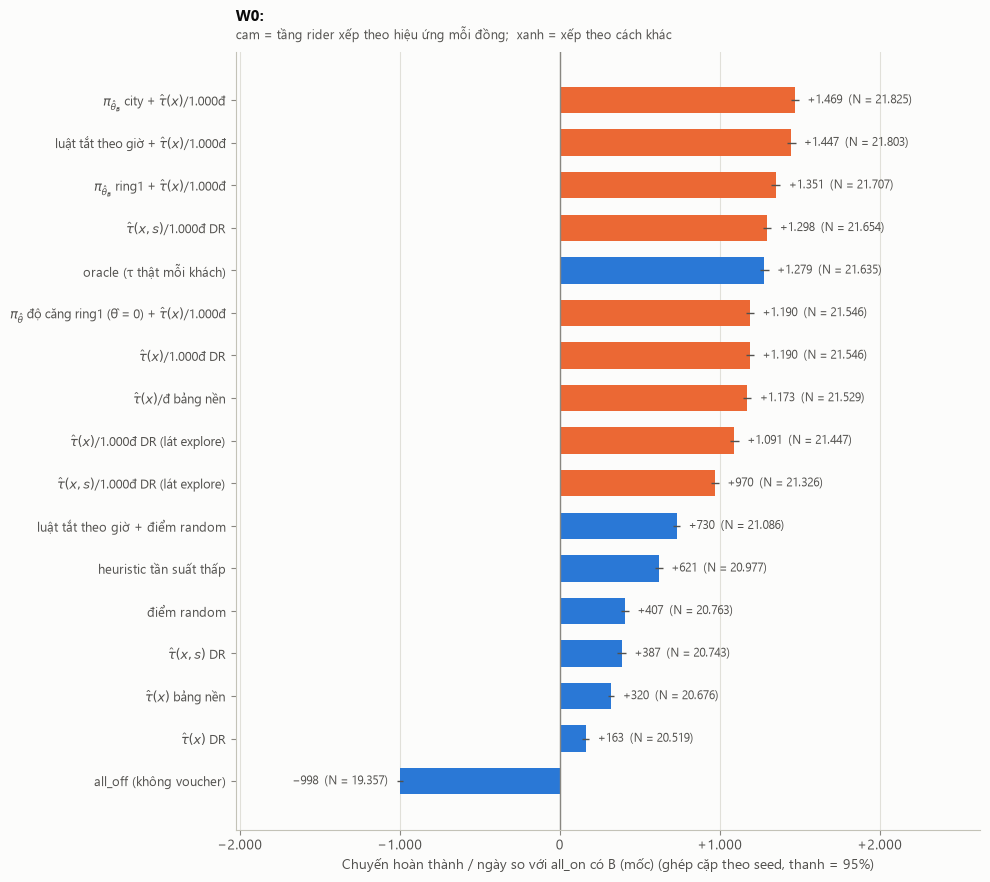

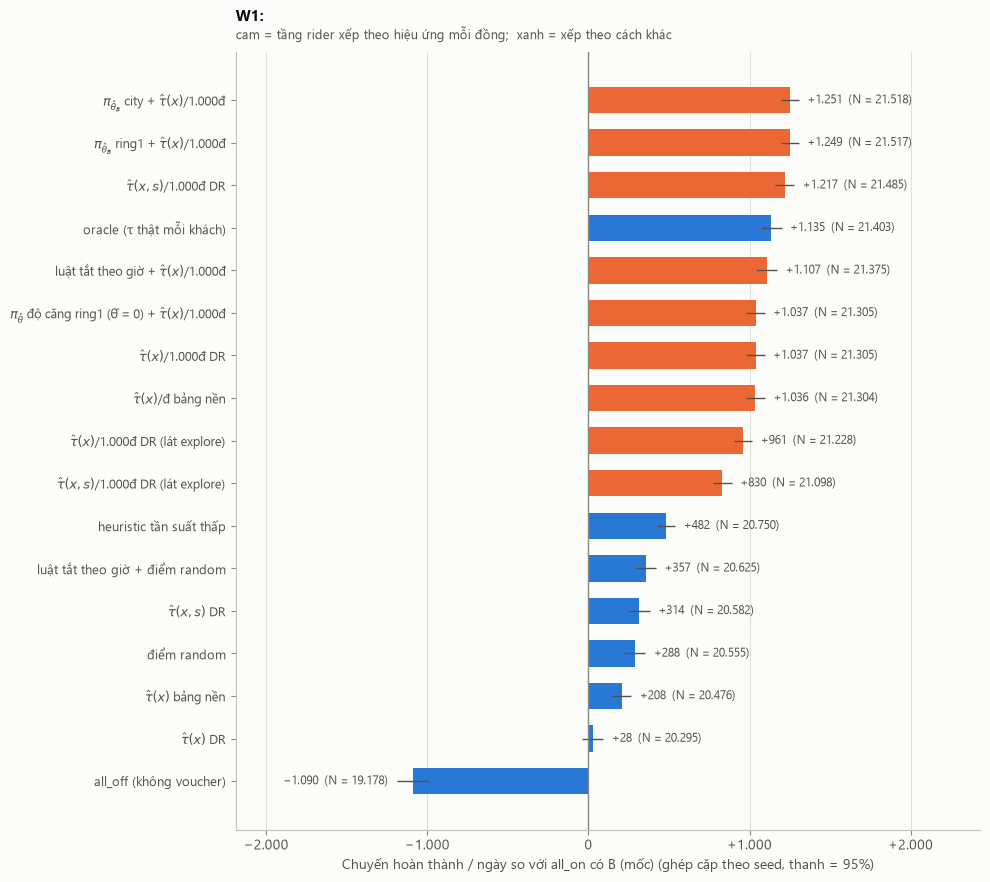

In [4]:
for w in ("W0", "W1"):
    fig = figures.ladder_figure(summary[w])
    fig.axes[0].set_title(f"{w}: " + fig.axes[0].get_title(), pad=22)
    save_figure(fig, f"02_n_duoi_b_{w.lower()}")
    plt.show()


### Khoảng cách `all_on` → oracle đã lấp

`gap_closed` = (N(π) − N(`all_on_B`)) / (N(oracle) − N(`all_on_B`)), tính trên trung bình theo seed, khoảng 95% bootstrap theo seed (`analysis.evaluation.gap_closed`).


In [5]:
gaps = pd.concat([evaluation.gap_table(r).assign(world=w) for w, r in runs.items()])
gaps.pivot(index="label", columns="world", values=["dN_vs_ref", "gap_closed", "ci_lo", "ci_hi"]).round(2)


dN_vs_ref          gap_closed       ci_lo       ci_hi      
world                           W0       W1         W0    W1    W0    W1    W0    W1
label                                                                               
all_off                    -998.50 -1089.80      -0.78 -0.96 -0.81 -1.08 -0.75 -0.85
heuristic                   621.20   481.97       0.49  0.42  0.47  0.39  0.50  0.46
hour_off_dr_kvnd           1446.97  1107.13       1.13  0.98  1.11  0.96  1.15  1.00
hour_off_random             730.47   356.87       0.57  0.31  0.56  0.27  0.59  0.36
oracle                     1278.70  1135.33       1.00  1.00  1.00  1.00  1.00  1.00
pi_hourB_city_dr_kvnd      1469.40  1250.53       1.15  1.10  1.12  1.07  1.18  1.14
pi_hourB_ring1_dr_kvnd     1350.87  1249.37       1.06  1.10  1.03  1.07  1.08  1.14
pi_tension_ring1_dr_kvnd   1190.33  1037.30       0.93  0.91  0.91  0.89  0.95  0.94
random                      407.27   287.77       0.32  0.25  0.30  0.21  0.33  0.30
tau_per_vnd                1173.17  1036.47       0.92  0.91  0.90  0.89  0.93  0.94
tau_x                       320.47   208.27       0.25  0.18  0.24  0.14  0.27  0.22
tau_x_dr_all                162.70    27.60       0.13  0.02  0.11 -0.04  0.14  0.08
tau_x_dr_all_kvnd          1190.33  1037.30       0.93  0.91  0.91  0.89  0.95  0.94
tau_x_dr_kvnd              1091.20   960.67       0.85  0.85  0.84  0.82  0.87  0.87
tau_xs_dr_all               386.73   314.30       0.30  0.28  0.28  0.22  0.32  0.33
tau_xs_dr_all_kvnd         1297.70  1217.40       1.01  1.07  0.99  1.03  1.04  1.12
tau_xs_dr_kvnd              970.00   830.13       0.76  0.73  0.75  0.71  0.77  0.75

**Đọc kết quả.**

- **W0** (B = 113,76 triệu đ/kỳ, N − `all_on_B` ± SE): `all_off` −998; `random` +407; `heuristic` +621; bảng nền /đ +1.173; tầng rider DR theo 1.000đ **+1.190** (τ̂(x)) và **+1.298** (τ̂(x, s)); DR theo chuyến (không chia tiền) chỉ +163 / +387; oracle **+1.279**. Tầng vùng θ̂_tension = 0 trùng tầng rider (không tắt ô nào); **θ̂_B `ring1` 2,3: +1.351; θ̂_B `city` 1,6: +1.469 ± 13** (tắt 51% / 35% (ô, slot)); luật giờ + DR **+1.447**; luật giờ + random +730. Khoảng cách `all_on` → oracle đã lấp: tầng rider 93–101%, tầng vùng `city` 115%, luật giờ 113%.
- **W1** (B = 116,13 triệu): tầng rider +1.037 / +1.217; oracle +1.135; **θ̂_B `ring1` 2,15: +1.249 ± 29; `city` 2,1: +1.251**; luật giờ + DR +1.107; luật giờ + random +357; `all_off` −1.090. Đã lấp: tầng vùng 110%, luật giờ 97%.
- Mọi chính sách có voucher đều tiêu gần hết B (cột Chi / B), trừ các dòng tầng vùng tắt nhiều (ô, slot). Xếp rider theo **hiệu ứng mỗi 1.000đ** vẫn là bậc lớn nhất; đưa trạng thái cung s vào hàm điểm thêm +108 (W0) / +180 (W1).


## 2. Bậc thang và hai giả thuyết H1, H2

θ\* luôn báo **kèm hàm điểm, B và bậc thang này**. Mỗi bậc là hiệu ghép cặp theo seed giữa hai chính sách chỉ khác một lớp. Hai giả thuyết ghi trước khi sinh dữ liệu: **H1** W0: chính sách theo độ căng ngang luật tắt theo giờ; **H2** W1: chính sách theo độ căng thắng, CI 95% không chứa 0 *và* lợi ích tập trung vào các slot có biến động (mục 7).


In [6]:
steps = [
    ("all_on_B", "random", "rải ngân sách cả ngày (κ chặn theo điểm ngẫu nhiên)"),
    ("random", "tau_per_vnd", "xếp rider theo hiệu ứng mỗi đồng (bảng nền)"),
    ("tau_per_vnd", "tau_x_dr_all_kvnd", "thay bảng nền bằng DR-learner /1.000đ"),
    ("tau_x_dr_all", "tau_x_dr_all_kvnd", "cùng DR: chia cho chi kỳ vọng thay vì theo chuyến (P2)"),
    ("tau_x_dr_all_kvnd", "tau_xs_dr_all_kvnd", "đưa trạng thái cung s vào hàm điểm"),
    ("tau_x_dr_all_kvnd", "pi_hourB_ring1_dr_kvnd", "thay vào đó: tầng vùng ring1, θ̂_B"),
    ("tau_x_dr_all_kvnd", "pi_hourB_city_dr_kvnd", "thay vào đó: tầng vùng city, θ̂_B"),
    ("tau_x_dr_all_kvnd", "hour_off_dr_kvnd", "thay vào đó: luật tắt cố định theo giờ"),
    ("hour_off_dr_kvnd", "pi_hourB_ring1_dr_kvnd", "độ căng ring1 − luật giờ (H1 / H2)"),
    ("hour_off_dr_kvnd", "pi_hourB_city_dr_kvnd", "độ căng city − luật giờ (H1 / H2)"),
    ("oracle", "pi_hourB_ring1_dr_kvnd", "tầng vùng ring1 − oracle"),
    ("hour_off_random", "hour_off_dr_kvnd", "trong luật giờ: random → DR /1.000đ"),
]
ladders = []
for w, r in runs.items():
    lad = policy_table.paired_steps(r, [(a, b) for a, b, _ in steps]).assign(world=w)
    lad.insert(0, "bậc", [text for _, _, text in steps])
    ladders.append(lad)
pd.concat(ladders).pivot(index=["bậc"], columns="world", values=["diff", "diff_se"]).reindex([t for _, _, t in steps]).round(1)


diff         diff_se      
world                                                   W0      W1      W0    W1
bậc                                                                             
rải ngân sách cả ngày (κ chặn theo điểm ngẫu nh...   407.3   287.8    12.8  33.8
xếp rider theo hiệu ứng mỗi đồng (bảng nền)          765.9   748.7    11.8  14.2
thay bảng nền bằng DR-learner /1.000đ                 17.2     0.8     8.0   7.7
cùng DR: chia cho chi kỳ vọng thay vì theo chuy...  1027.6  1009.7    13.0  17.2
đưa trạng thái cung s vào hàm điểm                   107.4   180.1    10.3  17.1
thay vào đó: tầng vùng ring1, θ̂_B                   160.5   212.1    12.7  15.9
thay vào đó: tầng vùng city, θ̂_B                    279.1   213.2    12.8  17.5
thay vào đó: luật tắt cố định theo giờ               256.6    69.8    10.2   9.6
độ căng ring1 − luật giờ (H1 / H2)                   -96.1   142.2    10.4  16.3
độ căng city − luật giờ (H1 / H2)                     22.4   143.4    11.2  18.8
tầng vùng ring1 − oracle                              72.2   114.0    15.6  19.0
trong luật giờ: random → DR /1.000đ                  716.5   750.3    12.5  15.2

**Đọc kết quả.**

- Hai bậc lớn nhất trên cả hai thế giới là **rải ngân sách cả ngày** (+407 W0 / +288 W1) và **xếp rider theo hiệu ứng mỗi đồng** (+766 / +749 so với `random`); DR-learner /1.000đ hơn bảng nền ít (+17 / +1 với τ̂(x); +125 / +181 với τ̂(x, s)).
- **P2** (trần voucher 20.000đ làm chênh lệch "theo đồng − theo chuyến" nhỏ hơn trên thế giới cũ): cùng mô hình DR, chia cho chi kỳ vọng thêm **+1.028 (4,8% N) trên W0, +1.010 (4,7%) trên W1**, so với +237 (≈ 6,4% N) trên thế giới cũ. Theo phần trăm N, chênh lệch **nhỏ hơn**, đúng chiều dự đoán, nhưng vẫn là bậc lớn thứ hai.
- **H1 (W0)**: tầng vùng `city` − luật giờ = **+22 ± 11** (CI 95% [−1; +45], chứa 0) → ngang nhau; `ring1` − luật giờ = −96 ± 10 (kém). H1 đúng với `city`, và luật giờ thắng `ring1`.
- **H2 (W1)**: tầng vùng `ring1` − luật giờ = **+142 ± 16**, `city` − luật giờ +143 ± 19; CI không chứa 0 → vế thứ nhất của H2 đúng; vế "tập trung vào slot có biến động" kiểm ở mục 7.
- Luật giờ chỉ mạnh khi hàm điểm tốt: với `random`, luật giờ hơn `random` +323 (W0) nhưng chỉ +69 (W1); với DR/1.000đ thì +257 / +70. Trên W1 giờ có hại chỉ còn 18h nên luật giờ cắt được ít.


## 3. Đường N(π_θ) theo θ và dao động

π_θ tắt khuyến mãi ở (ô, slot) có độ căng dự báo ŝ < θ (`ring1`: tổng xe rảnh / tổng xe đi đón của ô và 6 ô kề), rồi phát cho rider có điểm τ̂(x)/1.000đ DR ≥ κ trong các ô còn bật; κ chọn lại cho từng θ để chi tiêu vừa B. Lưới 16 θ (`config/sweep_reference.yaml`), 30 seed.

Tập θ\* là các θ **không kém θ tốt nhất** ở mức 5% đồng thời (Bonferroni, ghép cặp theo seed). Để tránh winner's curse, θ còn được **chọn trên nửa seed** (seed chẵn / lẻ) và đo regret trên nửa còn lại (`analysis.evaluation.split_seed_regret`); "% lợi ích tối đa của tầng vùng lấy lại được" = (N(θ̂) − N(0)) / (max_θ N(θ) − N(0)).


In [7]:
sweeps = {w: pd.read_parquet(d / "results" / "policy_results.parquet") for w, d in (("W0", sweep_w0), ("W1", sweep_w1))}
theta_hats = {"W0": (2.3, 1.6), "W1": (2.15, 2.1)}
overview = pd.concat([sweep_overview({f"{w}: ring1, DR/1.000đ": s}, theta_hats=theta_hats[w]) for w, s in sweeps.items()])
display(overview.round(2))
split = pd.concat([evaluation.split_seed_regret(s).assign(world=w) for w, s in sweeps.items()])
display(split[["world", "chosen_on", "tested_on", "theta_chosen", "theta_best_heldout", "regret", "regret_se", "gain_recovered", "max_gain_heldout"]].round(2))
fixed = pd.DataFrame([{"world": w, **evaluation.gain_recovered(s, t)} for w, s in sweeps.items() for t in (0.0, *theta_hats[w])])
display(fixed.round(2))


,sweep,theta_best,mean_best,star_lo,star_hi,star_gaps,mean_theta0,n_seeds,regret_0,regret_0_se,regret_2.3,regret_2.3_se,regret_1.6,regret_1.6_se,regret_2.15,regret_2.15_se,regret_2.1,regret_2.1_se
0,"W0: ring1, DR/1.000đ",1.50,21827.30,1.25,1.5,[],21546.27,30,281.03,10.63,155.91,7.43,12.66,1.61,NaN,NaN,NaN,NaN
0,"W1: ring1, DR/1.000đ",1.25,21615.83,0.80,1.5,[],21304.97,30,310.87,18.14,NaN,NaN,NaN,NaN,119.23,14.55,103.23,14.67


,world,chosen_on,tested_on,theta_chosen,theta_best_heldout,regret,regret_se,gain_recovered,max_gain_heldout
0,W0,A,B,1.50,1.25,0.00,12.49,1.00,289.13
1,W0,B,A,1.25,1.50,13.67,12.01,0.95,272.93
0,W1,A,B,1.25,1.25,0.00,0.00,1.00,317.27
1,W1,B,A,1.25,1.25,0.00,0.00,1.00,304.47


,world,theta_hat,theta_best,N_0,N_best,N_theta_hat,max_gain,gain_recovered
0,W0,0.00,1.50,21546.27,21827.30,21546.27,281.03,0.00
1,W0,2.30,1.50,21546.27,21827.30,21671.39,281.03,0.45
2,W0,1.60,1.50,21546.27,21827.30,21814.64,281.03,0.95
3,W1,0.00,1.25,21304.97,21615.83,21304.97,310.87,0.00
4,W1,2.15,1.25,21304.97,21615.83,21496.60,310.87,0.62
5,W1,2.10,1.25,21304.97,21615.83,21512.60,310.87,0.67


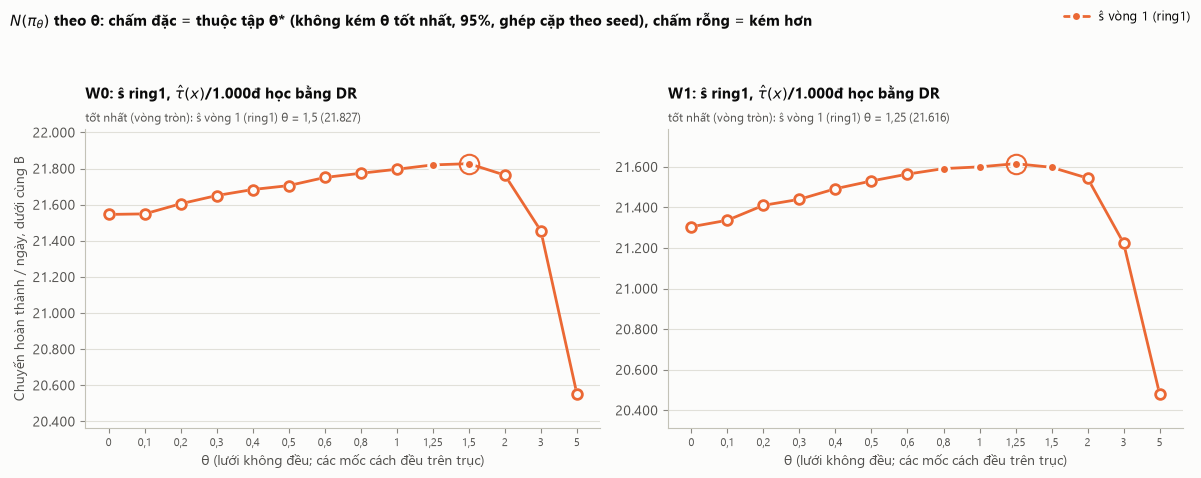

In [8]:
fig = figures.sweeps_figure({(f"{w}: ŝ ring1, " + figures.DR_TITLE.replace("/đ", "/1.000đ"), "ring1"): sweep_by_theta(s) for w, s in sweeps.items()})
save_figure(fig, "02_n_theo_theta")
plt.show()


In [9]:
switches = pd.concat([evaluation.switch_table(r).assign(world=w) for w, r in runs.items()])
switches[switches["switches_mean"] > 0][["world", "label", "theta", "switches_mean", "switches_median", "switches_p90", "share_cells_off",
                                          "hold_min_for_8_per_day", "hold_min_for_4_per_day"]].round(2)


,world,label,theta,switches_mean,switches_median,switches_p90,share_cells_off,hold_min_for_8_per_day,hold_min_for_4_per_day
13,W0,pi_hourB_ring1_dr_kvnd,2.30,23.71,23.81,24.63,0.51,180.0,360.0
14,W0,pi_hourB_city_dr_kvnd,1.60,13.40,14.00,16.00,0.35,180.0,360.0
13,W1,pi_hourB_ring1_dr_kvnd,2.15,21.10,21.51,23.06,0.47,180.0,360.0
14,W1,pi_hourB_city_dr_kvnd,2.10,19.47,19.00,26.20,0.44,180.0,360.0


**Đọc kết quả.**

- **W0**: N(θ) tăng từ 21.546 (θ = 0) tới đỉnh **21.827 ở θ = 1,5** (tập θ\* {1,25; 1,5}) rồi giảm (θ = 3: 21.455; θ = 5: 20.553, chi chỉ 57% B). Lợi ích tối đa của tầng vùng **+281 chuyến/ngày (+1,3%)**. Chọn θ trên nửa seed, đo trên nửa kia: chọn 1,5 → regret 0 ± 12 (lấy lại 100%); chọn 1,25 → 14 ± 12 (95%). θ̂ cố định của notebook 04: θ̂_B `ring1` 2,3 → regret 156 ± 7 (lấy lại 44%); θ̂_tension 0 → 281 (0%); 1,6 → 13 (95%).
- **W1**: đỉnh **21.616 ở θ = 1,25** (tập θ\* {0,8; 1,0; 1,25; 1,5}); lợi ích tối đa **+311 (+1,5%)**; chọn trên nửa seed → regret 0 cả hai chiều (100%); θ̂_B 2,15 → regret 119 ± 15 (62%); 2,1 → 103 (67%).
- θ̂_B của phương pháp theo giờ (notebook 04) cắt hơi quá (≈ 2,2 so với 1,25–1,5 tốt nhất) nhưng vẫn lấy lại 44–62% lợi ích tối đa; θ̂_tension = 0 không lấy lại gì vì trên hai thế giới này voucher không âm theo bin độ căng. Lưới θ 0–30 vẫn cho đủ ba đoạn tăng–phẳng–giảm.
- **Dao động**: θ̂_B `ring1` đổi trạng thái **23,7 lần/ô/ngày** trên W0 (trung vị 23,8; p90 24,6), `city` 13,4; W1: 21,1 / 19,5 — cao hơn mức 12 của tiêu chí A3. Với slot 15 phút, 24 lần/ngày tức đổi gần mỗi giờ; đề xuất giữ trạng thái tối thiểu **180 phút** (≤ 8 lần/ngày) hoặc 360 phút (≤ 4 lần), hoặc dùng `city` (ít hơn ~45%). Chưa đo N dưới ràng buộc giữ trạng thái (hạn chế).


## 4. Qini cao hơn mà N thấp hơn

Một nhóm làm uplift sẽ chọn hàm điểm theo **Qini** trên dữ liệu ngẫu nhiên hóa. Qini ở đây tính trên A/B theo rider 28 ngày (`runs/s8/<w>/rider_ab_28d`, kết cục hoàn thành chuyến), khoảng tin cậy bootstrap theo rider (200 lần). N lấy từ bảng ở mục 1 (π_θ θ = 0 với hàm điểm đó, dưới B); oracle bỏ qua vì không chấm được trên dữ liệu quan sát. `pi_tension_ring1_dr_kvnd` (θ̂ = 0) trùng `tau_x_dr_all_kvnd` nên chỉ vẽ một điểm.

Một cặp (a, b) là ví dụ khi Qini(a) > Qini(b) và N(a) < N(b), **cả hai hiệu có khoảng 95% không chứa 0**.


In [10]:
qini, efficiency, pairs = {}, {}, {}
for w, d in (("W0", qini_w0), ("W1", qini_w1)):
    res = d / "results"
    q = pd.read_parquet(res / "qini_completed.parquet")
    qini[w] = q[q["label"] != "pi_tension_ring1_dr_kvnd"]
    efficiency[w] = pd.read_parquet(res / "offer_efficiency.parquet")
    pairs[w] = {oc: pd.read_parquet(res / f"qini_pairs_{oc}.parquet") for oc in ("completed", "requested")}
    display(Markdown(f"**{w}** — Qini (hoàn thành) và N dưới B"))
    display(qini[w].assign(N_mean=qini[w]["label"].map(efficiency[w].set_index("label")["N_mean"]))
            .sort_values("qini_coef", ascending=False)[["label", "qini_coef", "qini_lo", "qini_hi", "N_mean"]].round(1))
    for oc, pr in pairs[w].items():
        print(f"{w} {oc}: {int(pr['qini_higher_n_lower'].sum())} / {len(pr) // 2} cặp có Qini cao hơn mà N thấp hơn")


**W0** — Qini (hoàn thành) và N dưới B

,label,qini_coef,qini_lo,qini_hi,N_mean
10,tau_xs_dr_all,9555.4,8602.6,10453.3,20742.7
7,tau_x_dr_all,7846.3,6771.0,9159.0,20518.6
6,tau_x,7129.2,6297.8,8128.0,20676.4
2,hour_off_random,5422.5,4942.9,5836.7,21086.4
1,hour_off_dr_kvnd,3344.0,2490.2,4222.8,21802.9
11,tau_xs_dr_all_kvnd,-87.8,-1504.3,1173.0,21653.6
4,random,-155.2,-489.8,269.8,20763.2
12,tau_xs_dr_kvnd,-1316.1,-2595.0,-99.6,21325.9
9,tau_x_dr_kvnd,-1722.5,-3147.9,-317.5,21447.1
5,tau_per_vnd,-2098.7,-3425.2,-717.9,21529.1


W0 completed: 50 / 78 cặp có Qini cao hơn mà N thấp hơn
W0 requested: 50 / 78 cặp có Qini cao hơn mà N thấp hơn


**W1** — Qini (hoàn thành) và N dưới B

,label,qini_coef,qini_lo,qini_hi,N_mean
10,tau_xs_dr_all,10095.0,9230.2,11052.9,20582.0
7,tau_x_dr_all,8065.4,6948.1,9253.9,20295.3
6,tau_x,7370.5,6388.3,8209.4,20475.9
2,hour_off_random,1649.2,1319.1,2040.4,20624.5
11,tau_xs_dr_all_kvnd,356.7,-938.5,1606.7,21485.1
4,random,-124.7,-499.7,269.0,20555.4
1,hour_off_dr_kvnd,-1090.5,-2474.6,226.7,21374.8
12,tau_xs_dr_kvnd,-1789.9,-3148.1,-572.2,21097.8
9,tau_x_dr_kvnd,-1967.4,-3373.8,-565.9,21228.3
5,tau_per_vnd,-2150.3,-3485.9,-961.5,21304.1


W1 completed: 46 / 78 cặp có Qini cao hơn mà N thấp hơn
W1 requested: 48 / 78 cặp có Qini cao hơn mà N thấp hơn


In [11]:
kvnd = {"tau_per_vnd", "tau_x_dr_all_kvnd", "tau_xs_dr_all_kvnd", "tau_x_dr_kvnd", "tau_xs_dr_kvnd", "hour_off_dr_kvnd"}
for w in ("W0", "W1"):
    pr = pairs[w]["completed"]
    inside = pr[pr["qini_higher_n_lower"] & pr["a"].isin(kvnd) & pr["b"].isin(kvnd)]
    display(Markdown(f"**{w}** — cặp đảo thứ tự *trong nhóm hàm điểm theo 1.000đ*"))
    display(inside.sort_values("dN")[["a", "b", "dqini", "dqini_lo", "dqini_hi", "dN", "dN_se"]].round(1))


**W0** — cặp đảo thứ tự *trong nhóm hàm điểm theo 1.000đ*

,a,b,dqini,dqini_lo,dqini_hi,dN,dN_se
152,tau_xs_dr_kvnd,tau_x_dr_all_kvnd,2521.7,1912.3,3136.0,-220.3,7.4
149,tau_xs_dr_kvnd,tau_per_vnd,782.6,121.9,1438.5,-203.2,8.7
153,tau_xs_dr_kvnd,tau_x_dr_kvnd,406.4,18.5,787.2,-121.2,7.1
116,tau_x_dr_kvnd,tau_x_dr_all_kvnd,2115.3,1420.1,2818.1,-99.1,8.5
67,tau_per_vnd,tau_x_dr_all_kvnd,1739.1,1092.9,2394.3,-17.2,8.0


**W1** — cặp đảo thứ tự *trong nhóm hàm điểm theo 1.000đ*

,a,b,dqini,dqini_lo,dqini_hi,dN,dN_se
152,tau_xs_dr_kvnd,tau_x_dr_all_kvnd,1588.3,915.8,2218.3,-207.2,10.2
116,tau_x_dr_kvnd,tau_x_dr_all_kvnd,1410.9,534.7,2071.2,-76.6,9.2


Để tách cơ chế, lấy đúng κ của mỗi hàm điểm trong bảng ở mục 1, coi session có điểm ≥ κ là "được phát", rồi đo trên chính dữ liệu A/B theo rider (chợ giữ nguyên, không có tranh chấp cung giữa hai nhánh): q₀, q₁ là tỷ lệ hoàn thành khi không và có voucher. Voucher chỉ trả khi chuyến hoàn thành, nên chi phí một lượt phát là v·q₁ và số chuyến thêm mỗi đồng là (1 − q₀/q₁)/v (`analysis.qini_vs_value.offer_efficiency`).


**W0**

| Hàm điểm | N dưới B | Session được phát | Voucher / lượt phát (đ) | q0 / q1 | Chuyến thêm / 100.000đ |
|---|---|---|---|---|---|
| `hour_off_dr_kvnd` | 21.802,9 | 35% | 17.945,47 | 0,077 / 0,138 | 2,83 |
| `tau_xs_dr_all_kvnd` | 21.653,6 | 37% | 17.961,31 | 0,065 / 0,121 | 2,99 |
| `pi_tension_ring1_dr_kvnd` | 21.546,3 | 40% | 17.954,82 | 0,062 / 0,117 | 3,01 |
| `tau_x_dr_all_kvnd` | 21.546,3 | 40% | 17.954,82 | 0,062 / 0,117 | 3,01 |
| `tau_per_vnd` | 21.529,1 | 40% | 17.954,96 | 0,063 / 0,119 | 3,04 |
| `tau_x_dr_kvnd` | 21.447,1 | 38% | 17.951,58 | 0,067 / 0,124 | 2,94 |
| `tau_xs_dr_kvnd` | 21.325,9 | 38% | 17.954,95 | 0,069 / 0,127 | 2,89 |
| `hour_off_random` | 21.086,4 | 23% | 17.946,82 | 0,130 / 0,199 | 2,12 |
| `heuristic` | 20.977,1 | 36% | 17.953,93 | 0,078 / 0,126 | 2,34 |
| `random` | 20.763,2 | 25% | 17.954,17 | 0,115 / 0,177 | 2,13 |
| `tau_xs_dr_all` | 20.742,7 | 11% | 17.948,97 | 0,222 / 0,316 | 1,77 |
| `tau_x` | 20.676,4 | 21% | 17.943,46 | 0,142 / 0,216 | 2,09 |
| `tau_x_dr_all` | 20.518,6 | 15% | 17.950,20 | 0,194 / 0,279 | 1,85 |

Spearman(N dưới B, chuyến thêm / 100.000đ ở mức cá nhân) = 0,802 trên 13 hàm điểm

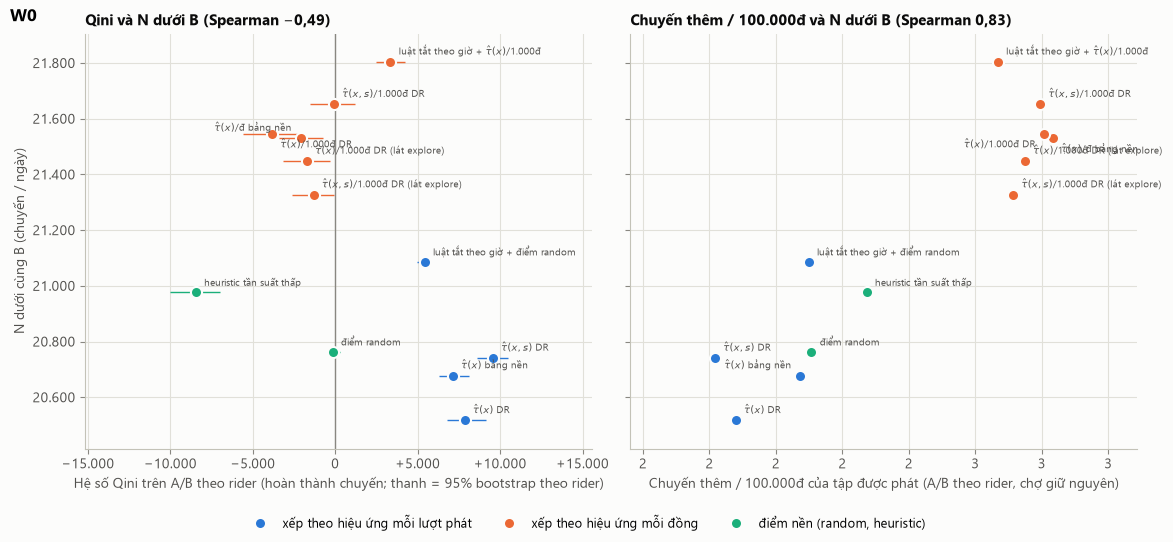

**W1**

| Hàm điểm | N dưới B | Session được phát | Voucher / lượt phát (đ) | q0 / q1 | Chuyến thêm / 100.000đ |
|---|---|---|---|---|---|
| `tau_xs_dr_all_kvnd` | 21.485,1 | 36% | 17.958,49 | 0,065 / 0,120 | 2,98 |
| `hour_off_dr_kvnd` | 21.374,8 | 38% | 17.951,48 | 0,066 / 0,122 | 2,96 |
| `pi_tension_ring1_dr_kvnd` | 21.305,0 | 40% | 17.955,65 | 0,062 / 0,116 | 3,01 |
| `tau_x_dr_all_kvnd` | 21.305,0 | 40% | 17.955,65 | 0,062 / 0,116 | 3,01 |
| `tau_per_vnd` | 21.304,1 | 40% | 17.954,01 | 0,061 / 0,116 | 3,04 |
| `tau_x_dr_kvnd` | 21.228,3 | 38% | 17.950,44 | 0,066 / 0,121 | 2,92 |
| `tau_xs_dr_kvnd` | 21.097,8 | 38% | 17.945,17 | 0,067 / 0,122 | 2,90 |
| `heuristic` | 20.749,6 | 36% | 17.954,68 | 0,076 / 0,123 | 2,32 |
| `hour_off_random` | 20.624,5 | 25% | 17.932,36 | 0,117 / 0,179 | 2,12 |
| `tau_xs_dr_all` | 20.582,0 | 11% | 17.952,37 | 0,222 / 0,317 | 1,78 |
| `random` | 20.555,4 | 25% | 17.933,14 | 0,113 / 0,174 | 2,14 |
| `tau_x` | 20.475,9 | 21% | 17.946,19 | 0,139 / 0,212 | 2,11 |
| `tau_x_dr_all` | 20.295,3 | 15% | 17.950,61 | 0,191 / 0,276 | 1,86 |

Spearman(N dưới B, chuyến thêm / 100.000đ ở mức cá nhân) = 0,857 trên 13 hàm điểm

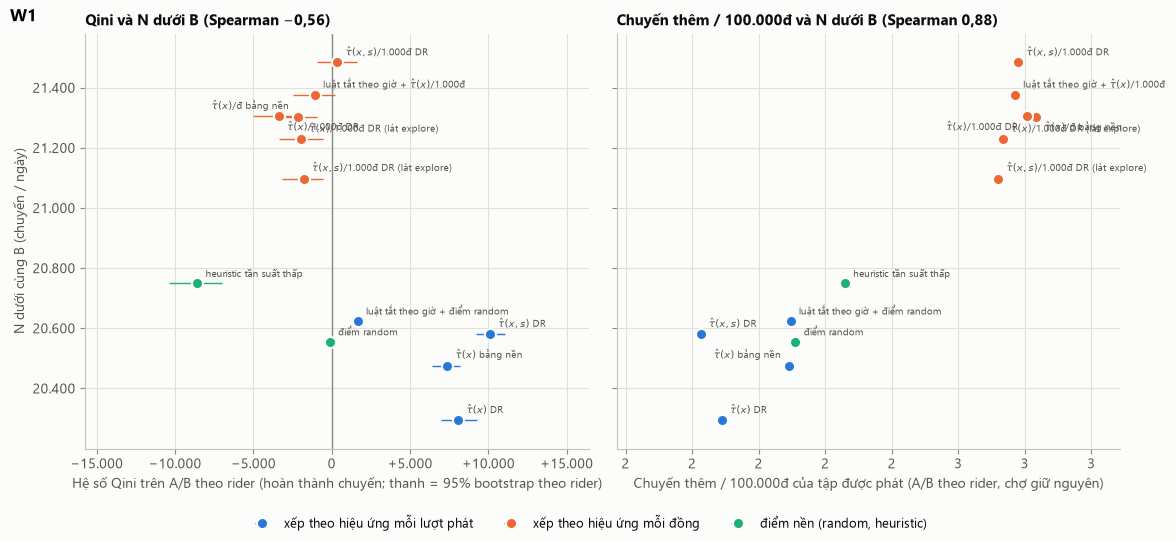

In [12]:
for w in ("W0", "W1"):
    display(Markdown(f"**{w}**\n\n" + efficiency_markdown(efficiency[w])))
    fig = figures.qini_vs_n_figure(qini[w], efficiency[w])
    fig.suptitle(w, x=0.01, ha="left", fontweight="bold")
    save_figure(fig, f"02_qini_va_n_{w.lower()}")
    plt.show()


**Đọc kết quả.**

- Trên cả 13 hàm điểm, Qini xếp **ngược** với N dưới B (Spearman −0,48 W0, −0,55 W1), còn "chuyến thêm / 100.000đ" đo ở mức cá nhân khớp N (Spearman **0,80 / 0,86**). Ba hàm Qini cao nhất (τ̂(x, s) DR, τ̂(x) DR, τ̂(x) bảng nền, Qini 7.100–10.100) đều nằm **cuối** bảng N: chúng chọn rider hay đi (q₀ 0,14–0,22 so với 0,06–0,08 của nhóm /1.000đ), uplift mỗi lượt phát lớn nhất nhưng phần lớn tiền trả cho chuyến đằng nào cũng có. Nhóm /1.000đ có Qini quanh 0 hoặc âm (voucher gần như đều 17.950đ nên khác biệt không nằm ở cỡ voucher).
- **Trong nhóm theo 1.000đ** (7 hàm), tương quan Qini–N chỉ 0,31 trên cả hai thế giới và vẫn có cặp đảo thứ tự với CI tách 0: bản học trên lát explore (`tau_xs_dr_kvnd`) có Qini cao hơn bản học trên toàn dữ liệu (`tau_x_dr_all_kvnd`) +2.522 [1.912; 3.136] (W0) / +1.588 [916; 2.218] (W1) nhưng N thấp hơn −220 ± 7 / −207 ± 10. Cơ chế vẫn là chi phí (q₀ 0,067–0,069 so với 0,062), không phải cung.
- **Ví dụ "lệch nhau do cung" trên W1:** τ̂(x, s)/1.000đ so với τ̂(x)/1.000đ: ở mức cá nhân (A/B theo rider, chợ giữ nguyên) chuyến thêm / 100.000đ **thấp hơn** (2,98 so với 3,01; W0 2,99 so với 3,01) nhưng dưới ngân sách trên thị trường thật N **cao hơn +180 ± 17** (W0 +108 ± 10). Phần chênh này không đo được bằng bất kỳ chỉ số cá nhân nào (Qini hay hiệu suất) vì nó đến từ việc hàm điểm đọc trạng thái cung s và dồn voucher sang nơi có xe. Trên W1 phần này gấp 1,7 lần W0 — cùng chiều với H2.
- Kết luận cho việc chọn hàm điểm: chọn theo Qini (τ̂(x, s) DR theo chuyến) thay vì bản /1.000đ của chính nó mất **911 chuyến/ngày (4,2%)** trên W0 và 903 trên W1; Qini có tính chi phí ("chuyến thêm / 100.000đ") là chỉ số sàng lọc đúng, và phần do cung phải đo bằng mô phỏng dưới B.


## 5. Độ vững trên W1

Chính sách khuyến nghị (tầng vùng `ring1` θ̂_B = 2,15 + τ̂(x)/1.000đ DR) so với tầng rider cùng hàm điểm và `all_on_B`, trên lưới B ∈ {0,3; 0,6; 1,0} × đội xe {1.278; 1.061; 856} (100 / 83 / 67%), 30 seed; và bảng 18 dòng trên ba `world_seed` (20260930 gốc, 20260931, 20260932).


In [13]:
robust = evaluation.stack_tables(robust_dirs, labels=["tier_dr_kvnd", "pi_hourB_ring1"])
display(robust.pivot(index=["budget_fraction", "fleet_size"], columns="label", values=["dN_vs_ref", "dN_vs_ref_se"]).round(0))
worldseed = evaluation.stack_tables([table_w1, ws1, ws2],
                                  labels=["tau_x_dr_all_kvnd", "tau_xs_dr_all_kvnd", "pi_hourB_ring1_dr_kvnd", "pi_hourB_city_dr_kvnd", "hour_off_dr_kvnd", "oracle"])
display(worldseed.pivot(index="label", columns="world_seed", values=["dN_vs_ref", "dN_vs_ref_se"]).round(0))


dN_vs_ref                dN_vs_ref_se             
label                      pi_hourB_ring1 tier_dr_kvnd pi_hourB_ring1 tier_dr_kvnd
budget_fraction fleet_size                                                        
0.3             856                 638.0        582.0           21.0         33.0
                1061                929.0        860.0           21.0         24.0
                1278               1249.0       1037.0           29.0         29.0
0.6             856                  29.0         53.0           54.0         28.0
                1061               -226.0        163.0           31.0         24.0
                1278               -114.0        304.0           22.0         32.0
1.0             856                 385.0          0.0           84.0          0.0
                1061               -383.0          0.0           85.0          0.0
                1278               -952.0          0.0           60.0          0.0

dN_vs_ref                   dN_vs_ref_se                  
world_seed              20260930 20260931 20260932     20260930 20260931 20260932
label                                                                            
hour_off_dr_kvnd          1107.0   1162.0   1080.0         33.0     31.0     31.0
oracle                    1135.0   1181.0   1110.0         33.0     32.0     28.0
pi_hourB_city_dr_kvnd     1251.0   1203.0   1136.0         29.0     24.0     28.0
pi_hourB_ring1_dr_kvnd    1249.0   1248.0   1190.0         29.0     28.0     27.0
tau_x_dr_all_kvnd         1037.0   1105.0   1014.0         29.0     30.0     29.0
tau_xs_dr_all_kvnd        1217.0   1279.0   1158.0         31.0     31.0     34.0

**Đọc kết quả.**

- **B = 0,3** (mức học ngưỡng): tầng vùng thắng tầng rider ở mọi cỡ đội xe (+1.249 so với +1.037 với 1.278 xe; +929 / +860 với 1.061; +638 / +582 với 856). **B = 0,6**: tầng vùng **thua** (−114 / −226 / +29 so với +304 / +163 / +53 của tầng rider). **B = 1,0**: tầng rider = `all_on` (0), tầng vùng −952 / −383 / **+386** (chỉ còn có ích khi đội xe nhỏ 856 xe).
- **Ngưỡng học cho B = 0,3 không chuyển sang B lớn**: khi ngân sách đủ phát cho mọi người, cắt (ô, slot) theo độ căng chỉ bớt chuyến. θ̂_B vốn phụ thuộc B, nên chính sách khuyến nghị phải kèm B của nó.
- **Ba `world_seed`**: thứ tự giữ nguyên — tầng vùng `ring1` +1.249 / +1.248 / +1.190, luật giờ +1.107 / +1.162 / +1.080, oracle +1.135 / +1.181 / +1.110; độ căng − luật giờ = +142 / +86 / +110 (SE ≈ 16): H2 vế một đúng trên cả ba thế giới ngẫu nhiên.


## 6. Độ nhạy theo giả định Hà Nội

W0, 10 seed, năm dòng (`all_on_B`, `random`, tầng rider DR/1.000đ, tầng vùng `ring1` θ̂_B = 2,3, luật giờ + DR) dưới: hazard hủy ×0,5 / ×1 / ×2 (`cancel.base_per_min`, `slope_per_min2`; kiểm P1: tác hại của voucher đi chủ yếu qua kênh hủy), quãng đường trung bình ngắn (`dest_decay_rings` 1,9 ≈ 5 km) / dài (6,0), và hình cầu theo giờ phẳng hơn kiểu NYC TLC (độ lệch khỏi 1 co 50%). Giữ nguyên θ̂ và hàm điểm học trên W0 gốc.


In [14]:
sens = evaluation.stack_tables(sens_dirs)
sens.pivot(index="dir", columns="label", values=["dN_vs_ref", "dN_vs_ref_se"]).round(0).reindex([d.name for d in sens_dirs])


dN_vs_ref                                                dN_vs_ref_se                                               
label              all_on_B hour_off_dr pi_hourB_ring1 random tier_dr_kvnd     all_on_B hour_off_dr pi_hourB_ring1 random tier_dr_kvnd
dir                                                                                                                                   
sens_base               0.0      1447.0         1370.0  436.0       1212.0          0.0        24.0           30.0   17.0         24.0
sens_hazard_0p5         0.0      1595.0         1496.0  513.0       1237.0          0.0        25.0           32.0   16.0         26.0
sens_hazard_2           0.0      1250.0         1189.0  281.0       1050.0          0.0        19.0           29.0   14.0         25.0
sens_trip_L1p9          0.0      1558.0         1460.0  467.0       1235.0          0.0        18.0           20.0   22.0         15.0
sens_trip_L6            0.0      1126.0         1077.0  260.0        925.0          0.0        27.0           29.0   24.0         24.0
sens_profile_flat       0.0      1658.0         1392.0  750.0       1628.0          0.0        24.0           34.0   17.0         21.0

**Đọc kết quả.**

- Thứ tự giữ nguyên ở 5/6 biến thể: luật giờ + DR ≥ tầng vùng `ring1` θ̂_B > tầng rider > `random` > `all_on_B`. Mức lợi của tầng vùng so với tầng rider: +159 (gốc), +259 (hazard ×0,5), +140 (×2), +226 (quãng ngắn), +152 (quãng dài); với hình cầu phẳng tầng vùng **thua tầng rider −237** (θ̂_B = 2,3 học trên hình cầu hai đỉnh tắt 70% (ô, slot) khi không còn đỉnh) — ngưỡng là của thế giới đã học, không mang sang hình cầu khác.
- Hazard hủy (P1): lợi của luật giờ so với tầng rider là +357 (×0,5) / +235 (×1) / +200 (×2): **không tăng** theo hazard. Nhưng cấu phần của nó luôn là *bớt hủy*: luật giờ − tầng rider = −82 request, **−317 hủy**, +235 hoàn thành (gốc) — tác hại đi qua kênh hủy khi voucher kéo thêm request vào giờ thiếu xe, đúng cơ chế P1, song độ lớn của kênh không tỷ lệ với hazard vì hazard thấp cũng làm rider chờ lâu hơn và chiếm xe lâu hơn.


## 7. H2, vế thứ hai: lợi ích có dồn vào slot có biến động không

Hai chính sách của W1 chạy lại với log đầy đủ (10 seed, cùng B và κ pilot): tầng vùng `ring1` θ̂_B = 2,15 và luật giờ + DR. Với mỗi seed, N(a) − N(b) tách theo **slot yêu cầu**: slot "có biến động" là slot chồng lên một cơn mưa hoặc sự kiện trong `meta/shocks` (biến động theo ngày — cầu theo ngày, tài xế nghỉ — phủ cả ngày nên không tách được). So sánh lợi ích mỗi slot của hai nhóm, ghép cặp theo seed (`analysis.evaluation.shock_split_table`).


In [15]:
per_seed = evaluation.shock_split_table(h2_dir, "pi_hourB_ring1", "hour_off_dr")
display(per_seed.round(2))
h2 = evaluation.shock_split_summary(per_seed)
pd.Series(h2).round(3)


,seed,N_a,N_b,n_slots_shock,n_slots_quiet,share_slots_shock,gain_shock,gain_quiet,gain_total,share_gain_shock,gain_per_shock_slot,gain_per_quiet_slot
0,0,21349,21180,0,101,0.00,0.0,169.0,169.0,0.00,NaN,1.67
1,1,20193,19805,17,84,0.17,-145.0,533.0,388.0,-0.37,-8.53,6.35
2,2,20405,20127,16,85,0.16,-82.0,360.0,278.0,-0.29,-5.12,4.24
3,3,21938,21884,0,101,0.00,0.0,54.0,54.0,0.00,NaN,0.53
4,4,23735,23471,7,94,0.07,51.0,213.0,264.0,0.19,7.29,2.27
5,5,21763,21663,5,96,0.05,-19.0,119.0,100.0,-0.19,-3.80,1.24
6,6,21517,21520,0,101,0.00,0.0,-3.0,-3.0,-0.00,NaN,-0.03
7,7,22203,22225,9,92,0.09,-44.0,22.0,-22.0,2.00,-4.89,0.24
8,8,20462,20434,0,101,0.00,0.0,28.0,28.0,0.00,NaN,0.28
9,9,21565,21415,0,101,0.00,0.0,150.0,150.0,0.00,NaN,1.49


n_seeds                    10.000
n_seeds_with_shock          5.000
gain_total                140.600
gain_total_se              42.830
gain_shock                -23.900
gain_shock_se              17.300
gain_quiet                164.500
gain_quiet_se              53.528
share_slots_shock           0.053
share_slots_shock_se        0.021
gain_per_shock_slot        -3.012
gain_per_shock_slot_se      2.693
gain_per_quiet_slot         1.827
gain_per_quiet_slot_se      0.641
share_gain_shock           -0.170
rate_diff                  -5.877
rate_diff_se                3.264
rate_diff_lo              -14.936
rate_diff_hi                3.183
dtype: float64

**Đọc kết quả.**

- 10 seed × 1 ngày: tầng vùng hơn luật giờ **+141 ± 43** (cùng mức +142 của bảng 30 seed). Chỉ 5/10 ngày có mưa hoặc sự kiện trong cửa sổ, chiếm 5,3% số slot. Phần lợi ở slot có biến động là **−24 ± 17**, ở slot yên **+165 ± 54**; lợi mỗi slot: −3,0 ± 2,7 (có biến động) so với +1,8 ± 0,6 (yên); hiệu ghép cặp theo seed −5,9 ± 3,3, CI 95% [−14,9; +3,2]. Tách riêng: mưa −1,3 ± 3,3 so với +1,6; sự kiện −10,3 ± 3,8 so với +1,6.
- **Vế hai của H2 không đúng:** lợi ích của chính sách theo độ căng trên W1 *không* dồn vào slot mưa / sự kiện; trong các slot đó nó còn hơi kém luật giờ (θ̂_B = 2,15 tắt cả vùng quanh sự kiện, nơi cầu tăng ×2 nhưng xe vẫn đến được). Lợi ích nằm ở các slot thường: W1 có cầu theo ngày và tài xế nghỉ (mỗi seed một ngày, hệ số cầu 0,86–1,32, 111–152 xe nghỉ), nên vùng căng dịch chuyển theo ngày và luật giờ cố định (chỉ tắt 18h) bắt được ít; lợi theo seed không tương quan với hệ số cầu ngày (r = −0,04) và tương quan âm nhẹ với số xe nghỉ (r = −0,41, n = 10).
- Hạn chế: mỗi seed một ngày, 101 slot; biến động theo ngày không tách được theo slot. Kiểm trên 28 ngày cần chạy lại hai chính sách với `time.days_per_run` lớn hơn (ngoài ngân sách máy).


## Tóm tắt

1. Cùng ngân sách, chính sách tốt nhất hơn `all_on_B` **+1.469 chuyến/ngày (+7,2%)** trên W0 (tầng vùng `city` θ̂_B) và **+1.251 (+6,2%)** trên W1 (tầng vùng `ring1`/`city`), vượt oracle theo từng khách (+1.279 / +1.135) vì tầng vùng đổi cả thị trường. Gần toàn bộ phần lợi đến từ hai việc: rải chi tiêu cả ngày và xếp rider theo **hiệu ứng mỗi 1.000đ**; tầng vùng hoặc luật giờ thêm +150…+280.
2. **H1 đúng** (W0: độ căng `city` − luật giờ +22 ± 11, ≈ 0). **H2 chỉ đúng vế một** (W1: +142 ± 16, giữ trên ba `world_seed`); vế hai sai: lợi ích nằm ở slot thường (+165 ± 54), không ở slot mưa / sự kiện (−24 ± 17). Theo tiêu chí ghi trước khi chạy, H2 **chưa được xác nhận**; cơ chế thật là biến động theo ngày.
3. **P2 đúng về chiều**: chênh lệch "theo đồng − theo chuyến" còn 4,7–4,8% N (thế giới cũ: ≈ 6,4%) nhưng vẫn là bậc lớn. **P1**: tác hại đi qua kênh hủy (luật giờ bớt 317 hủy để thêm 235 chuyến), chỉ số cục bộ ≈ `system` (notebook 04, mục 2), nhưng lợi của luật giờ không tăng theo hazard.
4. Qini xếp hàm điểm **ngược** với N dưới ngân sách; "chuyến thêm / 100.000đ" khớp. Riêng phần do **cung** (τ̂(x, s) so với τ̂(x), cùng /1.000đ) không chỉ số cá nhân nào thấy: +108 (W0) / +180 (W1).
5. Ngưỡng θ̂_B là của B và thế giới đã học: thua khi B ≥ 0,6 hoặc hình cầu phẳng; chọn θ trên nửa seed rồi đo nửa kia cho regret ≈ 0. Khuyến nghị: tầng vùng `city` (ít dao động hơn `ring1` ~45%) + τ̂(x)/1.000đ DR, θ chọn lại theo B vận hành, giữ trạng thái ≥ 180 phút.
